For the regression task, i would be using the "Auto MPG dataset" downloaded from kaggle. It is a CSV file and the goal is to predict a car’s fuel efficiency, measured in miles per gallon (mpg), from variouse car characteristics.

The dataset contains information about cars, including engine specifications, weight, acceleration, model year, origin, and fuel efficiency. So the regression analysis will be used to determine or investigate how vehicle characteristics relate to fuel consumption. A higher MPG will means the car travels farther on one gallon of fuel.

**Understand Supervised Learning Concepts**

Supervised learning uses labeled data, where the correct output is known, to train models for prediction such as predicting MPG from labelled vehicle records. while unsupervised learning uses unlabeled data to discover hidden patterns, similarities, or groups without predefined outcomes such as grouping vehicles with similar characteristics using clustering.

**Data Preparation**
Import the necessary libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

**Load and inspect the dataset**

In [2]:
df = pd.read_csv("auto-mpg.csv", na_values=["?", " ?"])

# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(r"[\s-]+", "_", regex=True)
)

print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
df.info()

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1              amc rebel sst  
4          70       1                ford torino  

Dataset shape: (398, 9)

Column names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null

**Perform exploratory data analysis (EDA)**

In [3]:
numeric_columns = [
    "mpg", "cylinders", "displacement",
    "horsepower", "weight", "acceleration",
    "model_year"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Treat origin as a category rather than a numerical measurement
df["origin"] = df["origin"].astype("string").str.strip()
df["origin"] = df["origin"].replace({"?": pd.NA, "": pd.NA})


**Clean and preprocess the data**

In [4]:
# Convert missing categorical values to np.nan for the imputer
df["origin"] = df["origin"].astype(object)
df.loc[df["origin"].isna(), "origin"] = np.nan

print("Exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# Known targets are required for supervised training
df = df.dropna(subset=["mpg"])

Exact duplicate rows: 0


Note that there were only few missing values in the MPG columns (which is the target column), so i dropped it to work with the original MPG labels instead of imputing the values.


**Split the data into training and testing sets**

In [5]:
feature_columns = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year", "origin"
]

X = df[feature_columns]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (318, 7)
Testing features: (80, 7)


**Explore the training data only. This wioll prevent data leakage and keep the test set from being exposed**

In [6]:
train_df = X_train.copy()
train_df["mpg"] = y_train

print(train_df.describe())
print("\nMissing values:")
print(train_df.isna().sum())

print("\nOrigin counts:")
print(train_df["origin"].value_counts(dropna=False))

        cylinders  displacement  horsepower       weight  acceleration  \
count  318.000000    318.000000  313.000000   318.000000    318.000000   
mean     5.430818    191.904088  103.284345  2969.015723     15.639937   
std      1.684947    102.983802   37.361097   840.617729      2.763269   
min      3.000000     68.000000   46.000000  1613.000000      8.000000   
25%      4.000000     98.500000   75.000000  2220.000000     13.900000   
50%      4.000000    148.500000   92.000000  2822.500000     15.500000   
75%      6.000000    259.500000  122.000000  3597.250000     17.300000   
max      8.000000    455.000000  225.000000  5140.000000     24.800000   

       model_year         mpg  
count  318.000000  318.000000  
mean    76.103774   23.608176  
std      3.603177    7.930574  
min     70.000000    9.000000  
25%     73.000000   17.500000  
50%     76.000000   22.450000  
75%     79.000000   29.725000  
max     82.000000   46.600000  

Missing values:
cylinders       0
displaceme

**Build preprocessing pipelines**

In [8]:
numeric_features = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year"
]

categorical_features = ["origin"]

numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        drop="first",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_features),
    ("categorical", categorical_preprocessing, categorical_features)
])

The median imputation is used to fill missing numerical values using training medians.
The mode imputation(most frequent) is used to fill missing categorical values with the most frequent training category.
One-hot encoding represents origin without implying that its category codes have numerical distances.

**Train baseline models**

In [9]:
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),
    "XGBoost": XGBRegressor(
        objective="reg:squarederror",
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        random_state=42,
        n_jobs=1
    )
}



**Applying Cross Valiadtion technic**

In [11]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_models = {}
baseline_rows = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    # Negative MSE is converted into RMSE for each fold
    negative_mse = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    fold_rmse = np.sqrt(-negative_mse)

    pipeline.fit(X_train, y_train)
    baseline_models[name] = pipeline

    baseline_rows.append({
        "Model": name,
        "CV RMSE": fold_rmse.mean(),
        "CV RMSE SD": fold_rmse.std()
    })

baseline_results = pd.DataFrame(baseline_rows)

print(
    baseline_results.sort_values("CV RMSE")
    .round(3)
    .to_string(index=False)
)

            Model  CV RMSE  CV RMSE SD
          XGBoost    2.778       0.129
    Random Forest    2.984       0.114
Linear Regression    3.478       0.224
    Decision Tree    3.900       0.362
    Mean Baseline    7.923       0.557


All trained models performed substantially better than the mean baseline. However, the XGBoost has the lowest validation error meaning it performed best during cross-validation in predicting fuel efficinecy in MPG using teh car charatheristics. 
The CV RMSE SD measures how much performance varied across validation folds.

**Tune hyperparameters with GridSearchCV**

In [12]:
parameter_grids = {
    "Decision Tree": {
        "model__max_depth": [3, 5, None],
        "model__min_samples_leaf": [1, 3, 5]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [5, None],
        "model__min_samples_leaf": [1, 3]
    },
    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.03, 0.1]
    }
}

searches = {}
tuned_models = {}

for name, grid in parameter_grids.items():
    search = GridSearchCV(
        estimator=clone(baseline_models[name]),
        param_grid=grid,
        scoring="neg_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    searches[name] = search
    tuned_models[f"Tuned {name}"] = search.best_estimator_

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print(
        "Best CV RMSE:",
        round(np.sqrt(-search.best_score_), 3)
    )


Decision Tree
Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 5}
Best CV RMSE: 3.543

Random Forest
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV RMSE: 2.986

XGBoost
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV RMSE: 2.808


The GridSearchCV compares parameter combinations using training-set cross-validation and refits the best combination on all training data. the decision tree improved prediction performance from 3.900 to 3.543 while random forest remained unchanged at 2.984 and teh XGBOOST performed even worse than the cross validation technique


**Select a model using training CV results**

In [13]:
selection_rows = [
    {
        "Model": row["Model"],
        "CV RMSE": row["CV RMSE"]
    }
    for row in baseline_rows
]

for name, search in searches.items():
    selection_rows.append({
        "Model": f"Tuned {name}",
        "CV RMSE": np.sqrt(-search.best_score_)
    })

selection_results = (
    pd.DataFrame(selection_rows)
    .sort_values("CV RMSE")
)

all_models = {
    **baseline_models,
    **tuned_models
}

selected_name = selection_results.iloc[0]["Model"]
selected_model = all_models[selected_name]

print(selection_results.round(3).to_string(index=False))
print("\nSelected model:", selected_name)

              Model  CV RMSE
            XGBoost    2.778
      Tuned XGBoost    2.808
      Random Forest    2.984
Tuned Random Forest    2.986
  Linear Regression    3.478
Tuned Decision Tree    3.543
      Decision Tree    3.900
      Mean Baseline    7.923

Selected model: XGBoost


**Evaluate on the test set**

In [14]:
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)

    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(actual, predicted),
        "R2": r2_score(actual, predicted)
    }


test_rows = []

for name, model in all_models.items():
    predictions = model.predict(X_test)

    test_rows.append({
        "Model": name,
        **regression_metrics(y_test, predictions)
    })

test_results = pd.DataFrame(test_rows)

# Keep the training-CV order for the final comparison
test_results = (
    test_results.set_index("Model")
    .loc[selection_results["Model"]]
    .reset_index()
)

print(test_results.round(3).to_string(index=False))

              Model    MSE  RMSE   MAE     R2
            XGBoost  6.383 2.526 1.818  0.881
      Tuned XGBoost  6.820 2.611 1.818  0.873
      Random Forest  4.735 2.176 1.593  0.912
Tuned Random Forest  4.735 2.176 1.593  0.912
  Linear Regression  8.339 2.888 2.288  0.845
Tuned Decision Tree  7.223 2.688 1.996  0.866
      Decision Tree 11.462 3.386 2.294  0.787
      Mean Baseline 53.983 7.347 5.955 -0.004


using teh test dataset, the Random Forest achieved the best test performance, with:
MAE = 1.593 MPG: Predictions differed from actual fuel efficiency by approximately 1.59 MPG on average.
RMSE = 2.176 MPG: It had the lowest error when larger prediction mistakes receive more weight.
R² = 0.912: It explained approximately 91.2% of the variation in test-set MPG.

The XGBoost also performed well. However, it only explained 88.1% of test-set variation.

**Compare Actuall and predicted**

In [15]:
test_predictions = selected_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual MPG": y_test,
    "Predicted MPG": test_predictions
})

comparison["Residual"] = (
    comparison["Actual MPG"] -
    comparison["Predicted MPG"]
)

comparison["Absolute Error"] = comparison["Residual"].abs()

print(comparison.head(10).round(2))

     Actual MPG  Predicted MPG  Residual  Absolute Error
198        33.0      31.240000      1.76            1.76
396        28.0      29.879999     -1.88            1.88
33         19.0      21.290001     -2.29            2.29
208        13.0      15.570000     -2.57            2.57
93         14.0      13.250000      0.75            0.75
84         27.0      25.250000      1.75            1.75
373        24.0      27.030001     -3.03            3.03
94         13.0      12.280000      0.72            0.72
222        17.0      18.860001     -1.86            1.86
126        21.0      19.370001      1.63            1.63


**Visualize the result**

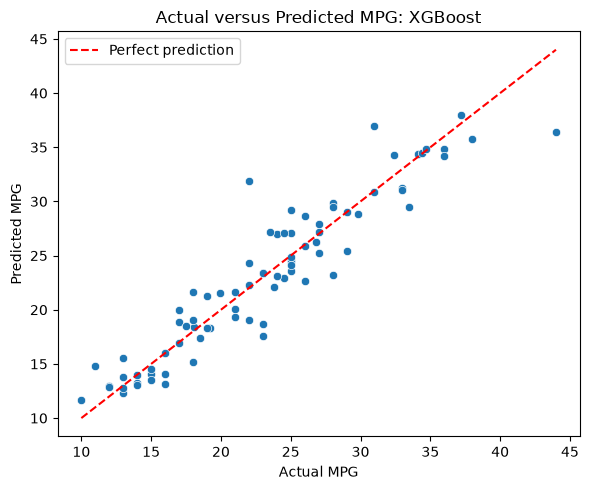

In [17]:
plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=comparison,
    x="Actual MPG",
    y="Predicted MPG"
)

lower = comparison[["Actual MPG", "Predicted MPG"]].min().min()
upper = comparison[["Actual MPG", "Predicted MPG"]].max().max()

plt.plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect prediction"
)

plt.title(f"Actual versus Predicted MPG: {selected_name}")
plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.legend()
plt.tight_layout()
plt.show()

Points close to the dashed line(regression line) indicate accurate predictions. Points above it represent overprediction; points below it represent underprediction.

For classification task, i will use the muchroom dataset from kaggle, the goal is to Predict whether a mushroom belongs to the edible or poisonous class using its characteristics. 
0 = Edible
1 = Poisonous

In [18]:
from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

In [19]:
#load the dataset 
df = pd.read_csv(
    "mushrooms.csv",
    na_values=["?", " "]
)

df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace("-", "_", regex=False)
)



In [22]:
df.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
8119    False
8120    False
8121    False
8122    False
8123    False
Length: 8124, dtype: bool

In [23]:
# Remove surrounding spaces from categorical values
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.strip()

df = df.replace("", np.nan)

print(df.head())
print("\nOriginal shape:", df.shape)
print("\nExact duplicate rows:", df.duplicated().sum())

# Avoid identical records appearing in both train and test
df = df.drop_duplicates()

# Keep records with valid, known labels
df = df[df["class"].isin(["e", "p"])].copy()

X = df.drop(columns="class")
y = df["class"].map({"e": 0, "p": 1}).astype(int)

  class cap_shape cap_surface cap_color bruises odor gill_attachment  \
0     p         x           s         n       t    p               f   
1     e         x           s         y       t    a               f   
2     e         b           s         w       t    l               f   
3     p         x           y         w       t    p               f   
4     e         x           s         g       f    n               f   

  gill_spacing gill_size gill_color  ... stalk_surface_below_ring  \
0            c         n          k  ...                        s   
1            c         b          k  ...                        s   
2            c         b          n  ...                        s   
3            c         n          n  ...                        s   
4            w         b          k  ...                        s   

  stalk_color_above_ring stalk_color_below_ring veil_type veil_color  \
0                      w                      w         p          w   
1       

C:\Users\tebos\AppData\Local\Temp\ipykernel_45808\1706834249.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


**Split before fitting preprocessing**

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (6499, 22)
Testing shape: (1625, 22)


**Exploratory data analysis**

In [26]:
print(X_train.head())
X_train.info()

print("\nCategorical summary:")
print(X_train.describe(include="all").T)

print("\nMissing values:")
print(X_train.isna().sum().sort_values(ascending=False))

print("\nNumber of categories per feature:")
print(X_train.nunique().sort_values())

print("\nClass counts:")
print(
    y_train.map({0: "Edible", 1: "Poisonous"})
    .value_counts()
)

     cap_shape cap_surface cap_color bruises odor gill_attachment  \
5249         f           y         y       f    f               f   
5781         x           s         p       t    n               f   
7586         b           s         g       f    n               f   
6181         f           s         n       f    s               f   
7338         k           y         n       f    f               f   

     gill_spacing gill_size gill_color stalk_shape  ...  \
5249            c         b          g           e  ...   
5781            c         b          e           e  ...   
7586            w         b          w           e  ...   
6181            c         n          b           t  ...   
7338            c         n          b           t  ...   

     stalk_surface_below_ring stalk_color_above_ring stalk_color_below_ring  \
5249                        k                      p                      b   
5781                        s                      e                    

**Class and feature distributions**

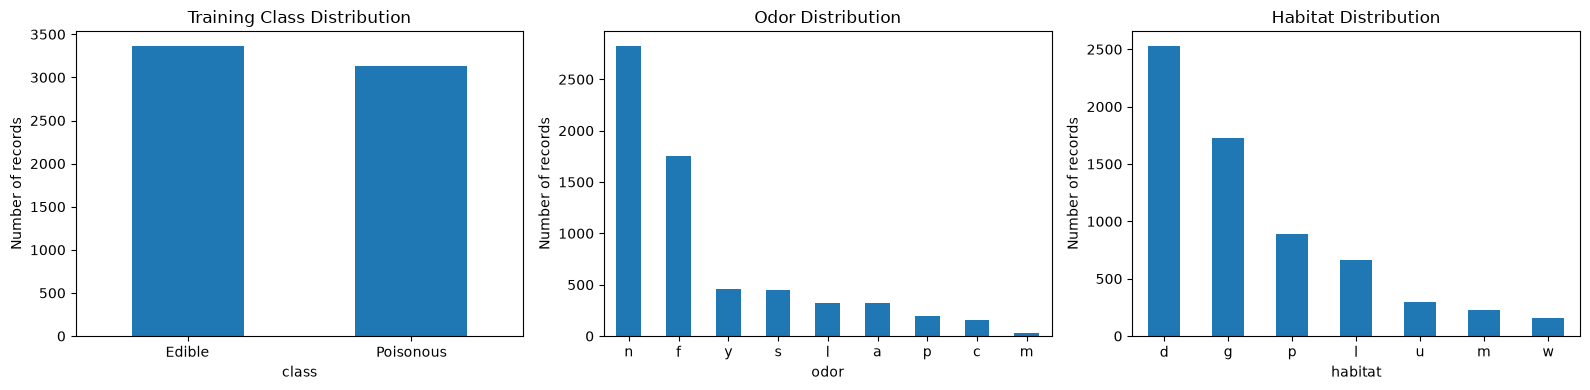

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

y_train.map({0: "Edible", 1: "Poisonous"}).value_counts().plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Training Class Distribution")
axes[0].set_ylabel("Number of records")

X_train["odor"].value_counts().plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_title("Odor Distribution")
axes[1].set_ylabel("Number of records")

X_train["habitat"].value_counts().plot(
    kind="bar", ax=axes[2], rot=0
)
axes[2].set_title("Habitat Distribution")
axes[2].set_ylabel("Number of records")

plt.tight_layout()
plt.show()

**Heatmap of a categorical relationship**

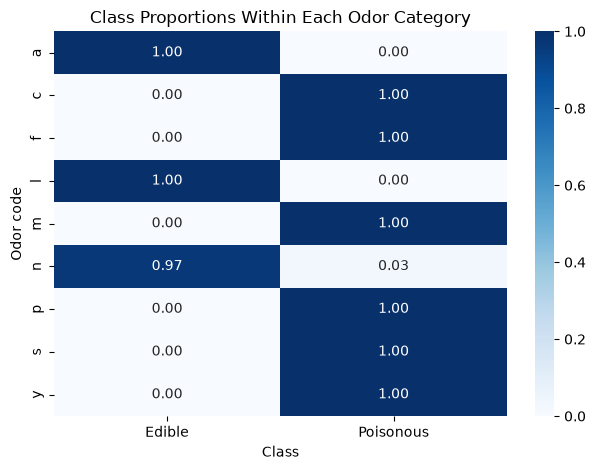

In [29]:
odor_table = pd.crosstab(
    X_train["odor"].fillna("Missing"),
    y_train.map({0: "Edible", 1: "Poisonous"}),
    normalize="index"
)

sns.heatmap(
    odor_table,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)

plt.title("Class Proportions Within Each Odor Category")
plt.xlabel("Class")
plt.ylabel("Odor code")
plt.tight_layout()
plt.show()

**Preprocess categorical features**

In [30]:
def build_pipeline(estimator, scale=False):
    steps = [
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]

    if scale:
        steps.append(
            ("scaler", StandardScaler(with_mean=False))
        )

    steps.append(("model", estimator))
    return Pipeline(steps)
    

**implement cross validation**

In [31]:
models = {
    "Majority Baseline": build_pipeline(
        DummyClassifier(strategy="most_frequent")
    ),
    "Logistic Regression": build_pipeline(
        LogisticRegression(
            max_iter=3000,
            random_state=42
        ),
        scale=True
    ),
    "Decision Tree": build_pipeline(
        DecisionTreeClassifier(random_state=42)
    ),
    "Random Forest": build_pipeline(
        RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        )
    ),
    "XGBoost": build_pipeline(
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=200,
            max_depth=3,
            learning_rate=0.1,
            tree_method="hist",
            random_state=42,
            n_jobs=1
        )
    ),
    "SVM": build_pipeline(
        SVC(kernel="rbf", C=1.0),
        scale=True
    )
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

cv_rows = []

for name, pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    row = {"Model": name}

    for metric in scoring:
        row[metric] = scores[f"test_{metric}"].mean()

    row["F1 SD"] = scores["test_F1"].std()
    cv_rows.append(row)

cv_results = pd.DataFrame(cv_rows)

print(
    cv_results.sort_values("F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

              Model  Accuracy  Precision  Recall     F1  ROC_AUC  F1 SD
      Random Forest    1.0000        1.0  1.0000 1.0000   1.0000 0.0000
            XGBoost    0.9998        1.0  0.9997 0.9998   1.0000 0.0003
      Decision Tree    0.9997        1.0  0.9994 0.9997   0.9997 0.0006
Logistic Regression    0.9997        1.0  0.9994 0.9997   0.9999 0.0006
                SVM    0.9995        1.0  0.9990 0.9995   0.9997 0.0010
  Majority Baseline    0.5179        0.0  0.0000 0.0000   0.5000 0.0000


**Tune with GridSearchCV**

In [32]:
parameter_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10]
    },
    "Decision Tree": {
        "model__max_depth": [3, 6, None],
        "model__min_samples_leaf": [1, 5]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, None]
    },
    "XGBoost": {
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.05, 0.1],
        "model__n_estimators": [100, 200]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01]
    }
}

searches = {}

for name, grid in parameter_grids.items():
    search = GridSearchCV(
        estimator=clone(models[name]),
        param_grid=grid,
        scoring=scoring,
        refit="F1",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    search.fit(X_train, y_train)
    searches[name] = search

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print("Best CV F1:", round(search.best_score_, 4))


Logistic Regression
Best parameters: {'model__C': 0.1}
Best CV F1: 0.9997

Decision Tree
Best parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 1}
Best CV F1: 0.9997

Random Forest
Best parameters: {'model__max_depth': None, 'model__n_estimators': 100}
Best CV F1: 1.0

XGBoost
Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV F1: 0.9998

SVM
Best parameters: {'model__C': 1, 'model__gamma': 'scale'}
Best CV F1: 0.9995


**Select the model before test evaluation**

In [37]:
candidates = {
    name: clone(pipeline).fit(X_train, y_train)
    for name, pipeline in models.items()
}

selection_rows = [
    {
        "Model": row["Model"],
        "CV F1": row["F1"]
    }
    for row in cv_rows
]

for name, search in searches.items():
    tuned_name = f"Tuned {name}"

    candidates[tuned_name] = search.best_estimator_

    selection_rows.append({
        "Model": tuned_name,
        "CV F1": search.best_score_
    })

selection_table = (
    pd.DataFrame(selection_rows)
    .sort_values("CV F1", ascending=False, kind="stable")
)

selected_name = selection_table.iloc[0]["Model"]
selected_model = candidates[selected_name]

print(selection_table.round(4).to_string(index=False))
print("\nSelected model:", selected_name)

                    Model  CV F1
            Random Forest 1.0000
      Tuned Random Forest 1.0000
                  XGBoost 0.9998
            Tuned XGBoost 0.9998
      Logistic Regression 0.9997
            Decision Tree 0.9997
Tuned Logistic Regression 0.9997
      Tuned Decision Tree 0.9997
                      SVM 0.9995
                Tuned SVM 0.9995
        Majority Baseline 0.0000

Selected model: Random Forest


**Evaluate test performance**

In [38]:
def positive_scores(model, X):
    if hasattr(model, "predict_proba"):
        positive_index = list(model.classes_).index(1)
        return model.predict_proba(X)[:, positive_index]

    return model.decision_function(X)


test_rows = []

for name, model in candidates.items():
    predictions = model.predict(X_test)
    scores = positive_scores(model, X_test)

    test_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, scores)
    })

test_results = pd.DataFrame(test_rows)

print(test_results.round(4).to_string(index=False))

                    Model  Accuracy  Precision  Recall     F1  ROC_AUC
        Majority Baseline    0.5182        0.0  0.0000 0.0000   0.5000
      Logistic Regression    1.0000        1.0  1.0000 1.0000   1.0000
            Decision Tree    1.0000        1.0  1.0000 1.0000   1.0000
            Random Forest    1.0000        1.0  1.0000 1.0000   1.0000
                  XGBoost    1.0000        1.0  1.0000 1.0000   1.0000
                      SVM    0.9988        1.0  0.9974 0.9987   1.0000
Tuned Logistic Regression    0.9988        1.0  0.9974 0.9987   1.0000
      Tuned Decision Tree    0.9988        1.0  0.9974 0.9987   0.9999
      Tuned Random Forest    1.0000        1.0  1.0000 1.0000   1.0000
            Tuned XGBoost    1.0000        1.0  1.0000 1.0000   1.0000
                Tuned SVM    0.9988        1.0  0.9974 0.9987   1.0000


The Majority Baseline achieved 51.82% accuracy by always predicting edible. A recall value andF1-score of 0.00 means it did not detect any of the poisonous mushrooms. 

Logistic Regression, Decision Tree, Random Forest, XGBoost, Tuned Random Fores and Tuned XGBoost all achieved 100% accuracy, precision, recall, and F1-score, indicating no classification errors on this test set.

SVM, Tuned Logistic Regression, Tuned Decision Tree, Tuned SVM did not achive 100% accuracy indicating that some poisonous muchrooms were inccorectly predicted as edible.

Tuning did not improve the model as it either remained thesame or performed worse worse.

**Classification report and confusion matrix**

Selected model: Random Forest
              precision    recall  f1-score   support

      Edible       1.00      1.00      1.00       842
   Poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



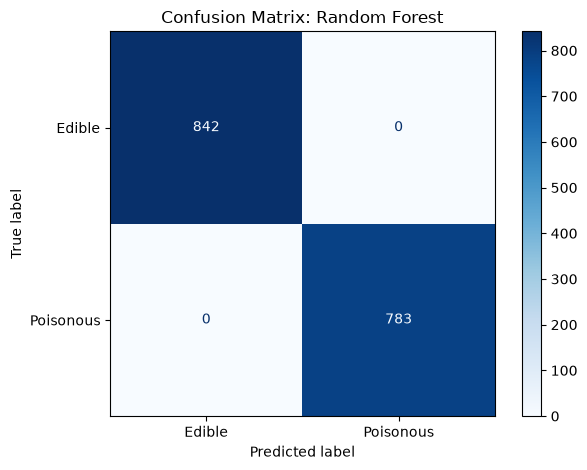

In [39]:
test_predictions = selected_model.predict(X_test)

print("Selected model:", selected_name)

print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["Edible", "Poisonous"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=[0, 1],
    display_labels=["Edible", "Poisonous"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix: {selected_name}")
plt.tight_layout()
plt.show()

Based on teh confusion matrix, 842 edible mushrooms were correctly predicted as edible,783 poisonous mushrooms were correctly predicted as poisonous.
There was No edible mushrooms that was incorrectly classified as poisonous. and there was no poisonous mushrooms that were incorrectly classified as edible.Therefore, random forest achive 100% test accuracy, 100% precision, 100% recall, and 100% F1-score.

**Plot ROC curves**

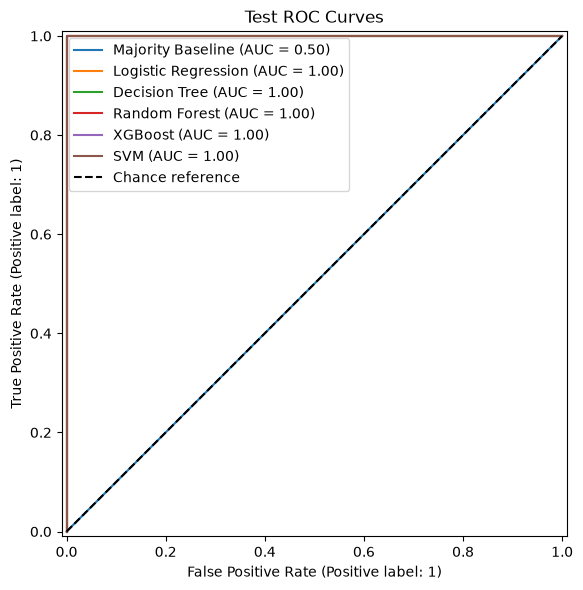

In [40]:
fig, ax = plt.subplots(figsize=(8, 6))

for name in models:
    model = candidates[name]

    RocCurveDisplay.from_predictions(
        y_test,
        positive_scores(model, X_test),
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Chance reference")
ax.set_title("Test ROC Curves")
ax.legend()
plt.tight_layout()
plt.show()

The ROC curves show that all five trained models correctly distinguish edible from poisonous mushrooms on this test set, with Aear Under Curve(AUC) values of 1.00.

**Compare actual and predicted classes**

In [42]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": test_predictions
})

comparison["Correct"] = (
    comparison["Actual"] == comparison["Predicted"]
)

comparison["Actual"] = comparison["Actual"].map({
    0: "Edible", 1: "Poisonous"
})

comparison["Predicted"] = comparison["Predicted"].map({
    0: "Edible", 1: "Poisonous"
})

print(comparison.head(15))

errors = comparison[~comparison["Correct"]]

print("\nNumber of errors:", len(errors))
print(errors.head(10))



         Actual  Predicted  Correct
4632  Poisonous  Poisonous     True
3444  Poisonous  Poisonous     True
1209     Edible     Edible     True
6880  Poisonous  Poisonous     True
4542  Poisonous  Poisonous     True
244      Edible     Edible     True
458      Edible     Edible     True
1315     Edible     Edible     True
980      Edible     Edible     True
2241  Poisonous  Poisonous     True
5843  Poisonous  Poisonous     True
3890  Poisonous  Poisonous     True
3677     Edible     Edible     True
3340     Edible     Edible     True
2468     Edible     Edible     True

Number of errors: 0
Empty DataFrame
Columns: [Actual, Predicted, Correct]
Index: []


All predicted muchroom class were the same as the actual muchroom class. the mdoel achieve 100% 